In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt


In [23]:
folder_path = r"G:\My Drive\no headstage vids"
prev_file = r"17L\17L_2025_05_27_15_20_41_stitchedDLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170"
curr_file = r"18R\18R_2025_06_29_15_43_01_stitchedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120"

In [24]:
print(folder_path + '\\' + prev_file + ".h5")

G:\My Drive\no headstage vids\17L\17L_2025_05_27_15_20_41_stitchedDLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170.h5


In [25]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_prev_file = pd.read_hdf(folder_path + '\\' + prev_file + ".h5")
h5_curr_file = pd.read_hdf(folder_path + '\\' + curr_file + ".h5")

In [26]:
h5_curr_file

scorer    DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120  \
bodyparts                                                     nose   
coords                                                           x   
0                                                1230.741333         
1                                                1231.298950         
2                                                1231.207153         
3                                                1231.240112         
4                                                1231.232422         
...                                                      ...         
36118                                            1231.593506         
36119                                            1231.440430         
36120                                            1231.395386         
36121                                            1231.396484         
36122                                            1231.396973         

scorer                                                                \
bodyparts                             midbody                          
coords              y likelihood            x           y likelihood   
0          948.518372   0.371378  1206.462891  920.733765   0.530892   
1          948.616699   0.400086  1207.110840  920.820496   0.508225   
2          948.670959   0.397238   154.060959   22.104786   0.521743   
3          948.646973   0.406646  1207.143433  920.784363   0.513702   
4          948.693481   0.402047  1207.125366  920.820679   0.512348   
...               ...        ...          ...         ...        ...   
36118      951.721252   0.325850   207.734787  163.237946   0.890444   
36119      951.425049   0.312743   207.167709  163.503143   0.874035   
36120      951.545288   0.327570   207.072754  163.931641   0.888528   
36121      951.554321   0.327531   207.332947  163.851089   0.872360   
36122      951.553589   0.327452   207.810867  164.592560   0.854063   

scorer                                                                 \
bodyparts    tailbase                               ear_R               
coords              x           y likelihood            x           y   
0           13.020819  275.981293   0.499788  1223.399536  935.649292   
1           12.357108  275.340485   0.476503  1223.617798  935.301147   
2           12.792274  275.185974   0.467112  1223.549683  935.424622   
3           12.434590  275.404388   0.482764  1223.569458  935.417969   
4           13.377718  275.564026   0.480986  1223.585815  935.431091   
...               ...         ...        ...          ...         ...   
36118      228.317337  161.642059   0.534005  1227.761963  937.658691   
36119      227.457184  162.145721   0.539995  1227.754517  937.693054   
36120      228.595718  161.552948   0.563300  1227.701904  937.557739   
36121      226.572372  160.938507   0.541644  1227.697021  937.554199   
36122      228.948669  161.378098   0.566673  1227.706909  937.560181   

scorer                                                    
bodyparts                   ear_L                         
coords    likelihood            x           y likelihood  
0           0.369980  1242.416626  936.092590   0.273334  
1           0.385643  1242.557495  936.068542   0.280873  
2           0.381299  1242.494629  936.076172   0.279176  
3           0.392692  1242.420898  936.148071   0.281293  
4           0.387559  1242.544556  936.201172   0.283910  
...              ...          ...         ...        ...  
36118       0.369262  1243.015503  938.984314   0.267365  
36119       0.365329   210.482620  175.262726   0.304911  
36120       0.368314   210.259933  174.175659   0.275984  
36121       0.368461   209.845490  175.074493   0.307422  
36122       0.368612   209.825699  174.906479   0.276080  

[36123 rows x 15 columns]

In [27]:
# Update to be the actual file name according to the first index column value of the h5 table
prev_file_name = 'DLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170'
curr_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'

# Load the DataFrame from the HDF5 file
dlc_raw_prev_h5 = h5_prev_file[prev_file_name]
dlc_raw_curr_h5 = h5_curr_file[curr_file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_prev_h5.iloc[0], dlc_raw_prev_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_prev_h5 = dlc_raw_prev_h5.apply(pd.to_numeric, errors='coerce')
dlc_raw_curr_h5 = dlc_raw_curr_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

prev_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_prev_h5)), columns=new_index)
curr_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_curr_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_prev_h5 = pd.concat([dlc_raw_prev_h5, prev_new_index_df], axis=1)
dlc_raw_curr_h5 = pd.concat([dlc_raw_curr_h5, curr_new_index_df], axis=1)

dlc_raw_prev_h5


nose                              ear_L                         \
                  x           y likelihood           x           y likelihood   
0       1235.605225  957.227600   0.087311  816.327820  443.941162   0.239814   
1        788.938171  431.775604   0.093751  804.113708  443.878448   0.306763   
2        779.502441  432.291321   0.058016  789.551636  442.395905   0.195495   
3       1238.406006  960.798401   0.054049  783.475769  443.431946   0.158369   
4        838.318970  436.322144   0.065074  773.008545  444.621460   0.165556   
...             ...         ...        ...         ...         ...        ...   
182625   113.387321  132.313721   0.338146   98.329529  142.495422   0.652792   
182626   111.152664  133.880615   0.513963   95.704735  144.547668   0.680929   
182627   108.987350  133.541336   0.567632   93.479866  143.663589   0.681279   
182628   108.260201  131.934387   0.546202   95.589119  145.499054   0.636772   
182629   108.381859  129.315323   0.610213   93.238739  141.964813   0.596690   

             ear_R                           mid_body  ...             \
                 x           y likelihood           x  ... likelihood   
0       816.563477  428.307861   0.336587  850.312561  ...   0.908538   
1       801.417236  426.424561   0.506755  838.360718  ...   0.915733   
2       786.527710  428.248688   0.361896  825.151855  ...   0.830025   
3       783.009399  428.559845   0.264582  814.211914  ...   0.853548   
4       771.854370  428.435608   0.248977  802.460266  ...   0.930024   
...            ...         ...        ...         ...  ...        ...   
182625  113.872520  145.066971   0.400696   95.396790  ...   0.721912   
182626  113.598511  145.581528   0.411799   95.122490  ...   0.716769   
182627  113.430115  144.806976   0.453913   94.791351  ...   0.720708   
182628  112.346169  145.761993   0.411591   95.570648  ...   0.692227   
182629  113.380951  143.065018   0.385497   95.547455  ...   0.688498   

         tail_base                          head_stage                         \
                 x           y likelihood            x           y likelihood   
0       884.242615  430.475067   0.739381   790.326477  435.590576   0.203722   
1       871.056030  428.966003   0.589424   780.394653  435.259308   0.156662   
2       860.502197  431.372528   0.719988   768.758972  437.365784   0.144136   
3       848.607117  427.443848   0.675166  1135.529053  649.975403   0.081795   
4       834.924744  430.793671   0.546661  1135.560059  649.898926   0.081170   
...            ...         ...        ...          ...         ...        ...   
182625   90.241829  183.819473   0.459062   119.382965  141.313751   0.193331   
182626   90.152672  184.177841   0.431439   117.140839  141.667267   0.286233   
182627   90.140221  184.249146   0.434850   104.973213  141.917145   0.334235   
182628   89.575790  184.139313   0.386946   103.656761  142.884766   0.343675   
182629   89.359978  184.067719   0.400385   102.826241  142.824097   0.402259   

       weighted                 
              x   y likelihood  
0           NaN NaN        NaN  
1           NaN NaN        NaN  
2           NaN NaN        NaN  
3           NaN NaN        NaN  
4           NaN NaN        NaN  
...         ...  ..        ...  
182625      NaN NaN        NaN  
182626      NaN NaN        NaN  
182627      NaN NaN        NaN  
182628      NaN NaN        NaN  
182629      NaN NaN        NaN  

[182630 rows x 21 columns]

In [28]:
dlc_raw_curr_h5

nose                             midbody                         \
                 x           y likelihood            x           y likelihood   
0      1230.741333  948.518372   0.371378  1206.462891  920.733765   0.530892   
1      1231.298950  948.616699   0.400086  1207.110840  920.820496   0.508225   
2      1231.207153  948.670959   0.397238   154.060959   22.104786   0.521743   
3      1231.240112  948.646973   0.406646  1207.143433  920.784363   0.513702   
4      1231.232422  948.693481   0.402047  1207.125366  920.820679   0.512348   
...            ...         ...        ...          ...         ...        ...   
36118  1231.593506  951.721252   0.325850   207.734787  163.237946   0.890444   
36119  1231.440430  951.425049   0.312743   207.167709  163.503143   0.874035   
36120  1231.395386  951.545288   0.327570   207.072754  163.931641   0.888528   
36121  1231.396484  951.554321   0.327531   207.332947  163.851089   0.872360   
36122  1231.396973  951.553589   0.327452   207.810867  164.592560   0.854063   

         tailbase                               ear_R                         \
                x           y likelihood            x           y likelihood   
0       13.020819  275.981293   0.499788  1223.399536  935.649292   0.369980   
1       12.357108  275.340485   0.476503  1223.617798  935.301147   0.385643   
2       12.792274  275.185974   0.467112  1223.549683  935.424622   0.381299   
3       12.434590  275.404388   0.482764  1223.569458  935.417969   0.392692   
4       13.377718  275.564026   0.480986  1223.585815  935.431091   0.387559   
...           ...         ...        ...          ...         ...        ...   
36118  228.317337  161.642059   0.534005  1227.761963  937.658691   0.369262   
36119  227.457184  162.145721   0.539995  1227.754517  937.693054   0.365329   
36120  228.595718  161.552948   0.563300  1227.701904  937.557739   0.368314   
36121  226.572372  160.938507   0.541644  1227.697021  937.554199   0.368461   
36122  228.948669  161.378098   0.566673  1227.706909  937.560181   0.368612   

             ear_L                        weighted                 
                 x           y likelihood        x   y likelihood  
0      1242.416626  936.092590   0.273334      NaN NaN        NaN  
1      1242.557495  936.068542   0.280873      NaN NaN        NaN  
2      1242.494629  936.076172   0.279176      NaN NaN        NaN  
3      1242.420898  936.148071   0.281293      NaN NaN        NaN  
4      1242.544556  936.201172   0.283910      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
36118  1243.015503  938.984314   0.267365      NaN NaN        NaN  
36119   210.482620  175.262726   0.304911      NaN NaN        NaN  
36120   210.259933  174.175659   0.275984      NaN NaN        NaN  
36121   209.845490  175.074493   0.307422      NaN NaN        NaN  
36122   209.825699  174.906479   0.276080      NaN NaN        NaN  

[36123 rows x 18 columns]

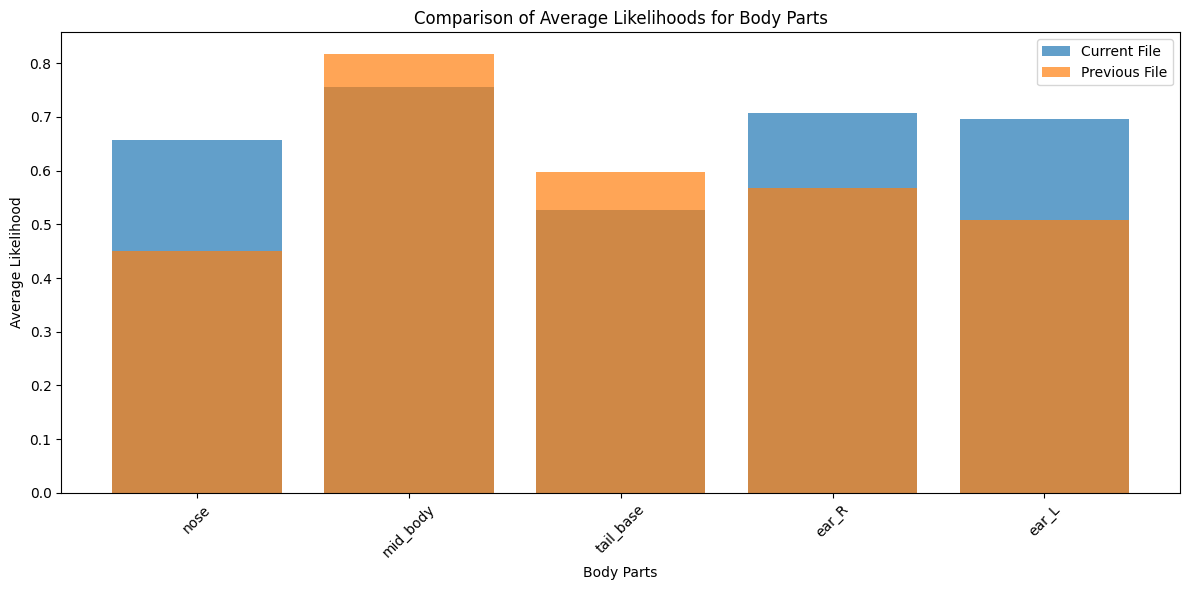

In [29]:
# Extract likelihood columns for both datasets
curr_likelihoods = dlc_raw_curr_h5.xs('likelihood', level=1, axis=1)
prev_likelihoods = dlc_raw_prev_h5.xs('likelihood', level=1, axis=1)

# Drop the 'weighted' column from both datasets
curr_likelihoods = curr_likelihoods.drop(columns=['weighted'])
prev_likelihoods = prev_likelihoods.drop(columns=['weighted', 'head_stage'])

# Rename columns to merge names with '_'
curr_likelihoods.columns = curr_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
prev_likelihoods.columns = prev_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
# Calculate average likelihoods for each body part
curr_avg_likelihoods = curr_likelihoods.mean()
prev_avg_likelihoods = prev_likelihoods.mean()

# Plot the average likelihoods for comparison
plt.figure(figsize=(12, 6))
plt.bar(curr_avg_likelihoods.index, curr_avg_likelihoods, alpha=0.7, label='Current File')
plt.bar(prev_avg_likelihoods.index, prev_avg_likelihoods, alpha=0.7, label='Previous File')
plt.xlabel('Body Parts')
plt.ylabel('Average Likelihood')
plt.title('Comparison of Average Likelihoods for Body Parts')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
import seaborn as sns

# Combine the likelihood data into a single DataFrame for plotting
combined_likelihoods = pd.concat([
    prev_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Previous'),
    curr_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Current')
])

# Create the violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=combined_likelihoods, x='Body Part', y='Likelihood', hue='File', split=True)
plt.title('Likelihood Distribution for Body Parts')
plt.xlabel('Body Parts')
plt.ylabel('Likelihood')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'